# Pandas Lab: reading online discussions

We work with **SynDisco**, a dataset of *synthetic* online discussions: seven simulated users debate a topic, and an LLM moderator may or may not step in. The same setup was run with 6 different LLMs and 4 moderation settings, 30 times each: **720 conversations**.

We learn pandas by asking simple questions about this data: how is it stored, who speaks, how long do the messages get, and what does the moderator change?

| Part | Topic | What we use |
|---|---|---|
| 1 | Loading and a first look | JSON files, `DataFrame`, `head`, `info`, `describe`, missing values |
| 2 | Selecting and summarising | `loc`, `iloc`, `explode`, `mean`, `median`, `value_counts`, `replace`, `map`, `clip` |
| 3 | Filtering and cleaning text | boolean masks, `.str`, regex, `drop`, `pop`, arithmetic between columns |
| 4 | Dates and times | `.dt`, differences between dates |
| 5 | Groups and joins | `groupby`, `concat`, `merge` |

**How to use this notebook.** Run the cells from top to bottom and read the short text between them. Every part ends with a **Your turn** exercise (write your own code in the empty cell, then open the solution) and a short list of findings. Each part is a heading, so you can collapse the ones you are not working on.

## Setup

Run **one** of the next two cells to download the data: the first on Colab, Linux or Mac, the second on any system (for example Windows). Then run the imports.

In [169]:
# download and unzip the data (Colab / Linux / Mac) -- on Windows run the next cell instead
!wget -q https://github.com/dimits-ts/syndisco/raw/master/viewer_datasets/online.zip
!unzip -qo online.zip

'wget' is not recognized as an internal or external command,
operable program or batch file.
'unzip' is not recognized as an internal or external command,
operable program or batch file.


In [170]:
# download and unzip the data (any OS, e.g. Windows) -- skip if you ran the cell above
import urllib.request
import zipfile

url = "https://github.com/dimits-ts/syndisco/raw/master/viewer_datasets/online.zip"
urllib.request.urlretrieve(url, "online.zip")

with zipfile.ZipFile("online.zip") as z:
    z.extractall()

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

## Part 1 · Loading and a first look

> **Goal.** Go from a folder of JSON files to one pandas table, and get to know it before touching it.

### 1.1 What is in the download?

The zip unpacks into one folder per **experiment**, a model run with one moderation setting: 6 models × 4 moderation settings = 24 folders (like `llama70b_vanilla.txt`; `nomod` means no moderator). Each folder has 30 JSON files, one per conversation. Let us open one.

In [2]:
# one folder per experiment, each with 30 json files (one per conversation)
folders = sorted(Path("online").iterdir())
files = sorted(folders[0].glob("*.json"))
print(len(folders), "folders;", len(files), "files in each folder")

# json.load turns the text of a json file into a Python dict
with open(files[0]) as f:
    raw = json.load(f)

print("\none file is a", type(raw).__name__, "with these keys:")
# the keys of the dict, with the type of each value
for key, value in raw.items():
    size = f" ({len(value)} items)" if isinstance(value, list) else ""
    print(f"  {key:<11} {type(value).__name__}{size}")

msg = raw["logs"][0]
print("\nthe first message of the conversation:")
print("  speaker:   ", msg["name"])
print("  written by:", msg["model"], " <- 'hardcoded' = a real comment copied from an online discussion, not a model")
print("  text:      ", msg["text"][:100] + "...")

24 folders; 30 files in each folder

one file is a dict with these keys:
  timestamp   str
  id          str
  users       list (7 items)
  moderator   str
  ctx_length  int
  logs        list (32 items)

the first message of the conversation:
  speaker:    grave-convergence
  written by: hardcoded  <- 'hardcoded' = a real comment copied from an online discussion, not a model
  text:       Not all Trump voters do it based out of hate and fear. What about all of his other messages? Making ...


### 1.2 From files to one table

The file is **nested**: `logs` is a list of messages, so `pd.read_json(file)` fails with `ValueError: All arrays must be of the same length`. Wrapping the dict in a list gives a table with one row, and a loop over all files gives one row per conversation. We add the folder name as an `experiment` column, so we remember which experiment each conversation came from. (We call it `experiment` and not `condition`: the folder name holds two things, the model and the moderation setting, and in Part 3 "condition" means something else, a test like `x > 3` that selects rows.)

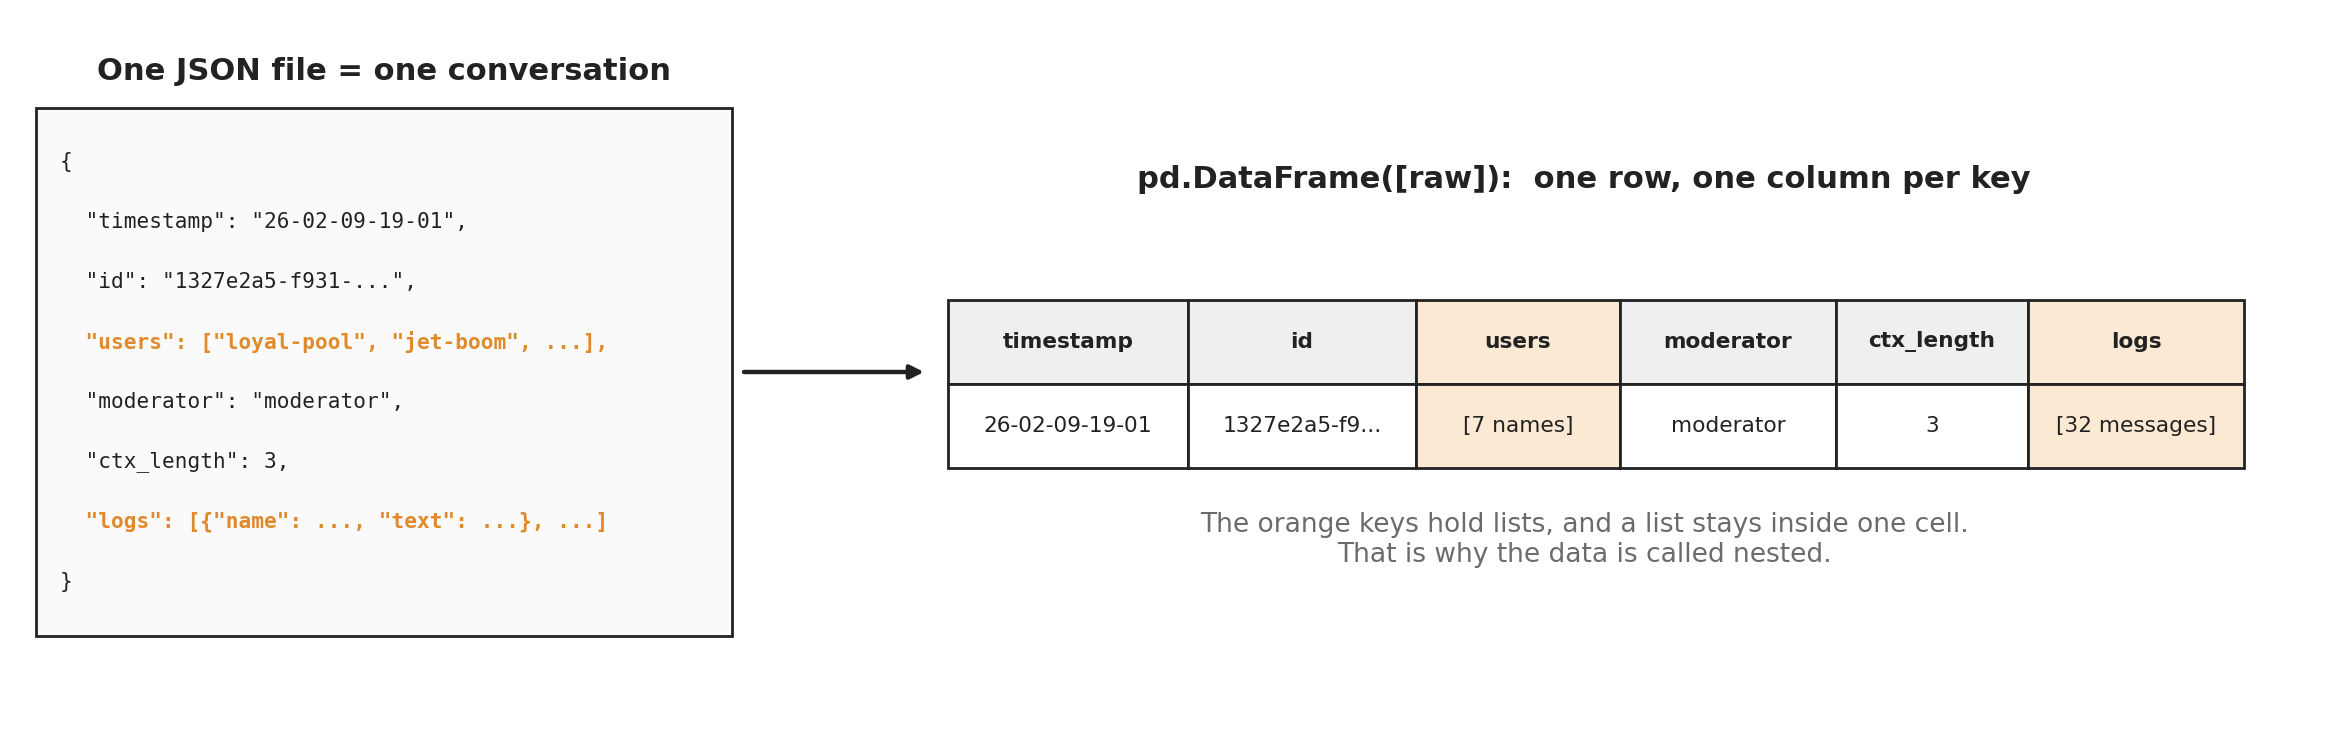

In [3]:
# one dict per conversation file, collected in a list
rows = []
for folder in folders:
    for file in sorted(folder.glob("*.json")):
        with open(file) as f:
            d = json.load(f)
        d["experiment"] = folder.name   # keep which experiment this file came from
        rows.append(d)

# a list of dicts becomes a table: one row per dict, one column per key
df = pd.DataFrame(rows)
print(f"Dataframe's shape: {df.shape}. Rows->{df.shape[0]}, Columns->{df.shape[1]}")


Dataframe's shape: (720, 7). Rows->720, Columns->7


In [4]:
# Display first n rows
df.head(3)

,timestamp,id,users,moderator,ctx_length,logs,experiment
0,26-02-09-19-01,1327e2a5-f931-4212-a1d9-b3efb7fb5348,"[loyal-pool, jet-boom, camel-conduit, grave-co...",moderator,3,"[{'name': 'grave-convergence', 'text': 'Not al...",llama70b_constructive_communications.txt
1,26-02-09-19-19,b3805d66-7317-44c0-99d8-d724b85d97ed,"[annoying-diffusion, noisy-centroid, eager-flo...",moderator,3,"[{'name': 'noisy-centroid', 'text': '&gt;And y...",llama70b_constructive_communications.txt
2,26-02-09-19-34,70da56c7-4b0d-4b19-823f-1b6914dc6ffa,"[exothermic-poset, coplanar-pouch, swarm-compr...",moderator,3,"[{'name': 'exothermic-poset', 'text': 'You can...",llama70b_constructive_communications.txt


In [5]:
# Display last n rows
df.tail(3)

,timestamp,id,users,moderator,ctx_length,logs,experiment
717,26-02-22-12-19,2eb157db-1382-4901-bdff-84620c0e3454,"[humid-engine, gentle-kayak, stern-buffet, con...",moderator,3,"[{'name': 'concave-remoulade', 'text': '&gt; I...",qwen7b_vanilla.txt
718,26-02-22-12-22,449f4d2b-7443-49e0-91db-430d222df5d9,"[round-synergy, impulsive-soda, optimal-trigge...",moderator,3,"[{'name': 'bare-turbine', 'text': '&gt; It is ...",qwen7b_vanilla.txt
719,26-02-22-12-24,cc1e33d9-dcb6-4e16-95f4-7f61c7e9cb23,"[isobaric-buyer, nearest-app, spry-garden, bro...",moderator,3,"[{'name': 'spry-garden', 'text': 'Like?', 'mod...",qwen7b_vanilla.txt


In [6]:
# Display random n rows
df.sample(3, random_state=42)

,timestamp,id,users,moderator,ctx_length,logs,experiment
340,26-02-10-20-52,de0c9805-cac0-4525-b28b-c8b724f967b8,"[huge-fur, ivory-cupola, wary-saturation, toug...",moderator,3,"[{'name': 'optimal-destination', 'text': '&gt;...",mistral24b_vanilla.txt
290,26-02-22-03-55,5358d487-d8d9-4367-802d-07cf59a61ee1,"[snow-boat, nervous-transom, heather-focus, in...",moderator,3,"[{'name': 'heather-focus', 'text': 'You're usi...",mistral24b_erulemaking.txt
54,26-02-22-02-28,d294759c-2b09-442b-965a-15aa7d6dd8f4,"[frosty-percussion, burning-bulkhead, kind-chi...",moderator,3,"[{'name': 'burning-bulkhead', 'text': 'I think...",llama70b_erulemaking.txt


### 1.3 Columns, types and statistics

`sample` shows rows from anywhere in the table (the table is sorted by folder, so the first rows alone are not representative). `info` lists the columns, their types and how many values are present. `describe` summarises the numeric columns.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   timestamp   720 non-null    object
 1   id          720 non-null    object
 2   users       720 non-null    object
 3   moderator   540 non-null    object
 4   ctx_length  720 non-null    int64 
 5   logs        720 non-null    object
 6   experiment  720 non-null    object
dtypes: int64(1), object(6)
memory usage: 39.5+ KB


`users` and `logs` hold whole lists inside a single cell. The only numeric column, `ctx_length`, is always 3, so it tells us nothing. `moderator` has fewer values than the rest: `isna` marks the missing ones, `sum` counts them.

In [8]:
df.describe()

,ctx_length
count,720.0
mean,3.0
std,0.0
min,3.0
25%,3.0
50%,3.0
75%,3.0
max,3.0


In [9]:
df.describe(include="all")

,timestamp,id,users,moderator,ctx_length,logs,experiment
count,720,720,720,540,720.0,720,720
unique,720,720,720,1,NaN,720,24
top,26-02-09-19-01,1327e2a5-f931-4212-a1d9-b3efb7fb5348,"[loyal-pool, jet-boom, camel-conduit, grave-co...",moderator,NaN,"[{'name': 'grave-convergence', 'text': 'Not al...",llama70b_constructive_communications.txt
freq,1,1,1,540,NaN,1,30
mean,NaN,NaN,NaN,NaN,3.0,NaN,NaN
std,NaN,NaN,NaN,NaN,0.0,NaN,NaN
min,NaN,NaN,NaN,NaN,3.0,NaN,NaN
25%,NaN,NaN,NaN,NaN,3.0,NaN,NaN
50%,NaN,NaN,NaN,NaN,3.0,NaN,NaN
75%,NaN,NaN,NaN,NaN,3.0,NaN,NaN


**Reading `describe`.** By default it summarises only the **numeric** columns: `count`, `mean`, `std`, `min`, the quartiles (25%, 50%, 75%) and `max`. Here that is just `ctx_length`, which is always 3, so the table says nothing new. With `include="all"` it also describes the **text** columns, using different statistics: `count` (values present), `unique` (different values), `top` (the most frequent value) and `freq` (how often it appears). The rows that do not apply to a column are `NaN`.

The text columns tell us two things. Every `id` is unique (720 of 720), so it identifies a conversation. `moderator` has 540 values and only 1 unique one, the word "moderator", so it only says present or absent. For `users` and `logs`, which hold lists, the summary is not useful: every list counts as a different value.

In [10]:
# Finding missing values
print("missing values per column:")
df.isna().sum()

missing values per column:


timestamp       0
id              0
users           0
moderator     180
ctx_length      0
logs            0
experiment      0
dtype: int64

**Is it really missing?** The 180 missing values are not an error: they are the conversations with **no moderator**, so the absence itself is the signal. As `NaN` it is awkward to count, so we turn it into an explicit 0/1 flag and drop the original column. The `timestamp` is still text; `to_datetime` makes it a real date (Part 4 uses it).

In [11]:
# notna() is True where a moderator exists; astype(int) turns True/False into 1/0
df["has_moderator"] = df["moderator"].notna().astype(int)
# the original column is no longer needed
df = df.drop(columns="moderator")

print("conversations with (1) and without (0) a moderator:")
print(df["has_moderator"].value_counts())
print("\ndistinct ids:", df["id"].nunique(), "out of", len(df), "conversations")

conversations with (1) and without (0) a moderator:
has_moderator
1    540
0    180
Name: count, dtype: int64

distinct ids: 720 out of 720 conversations


In [12]:
# text -> real datetime; format says where the year, month, day, hour and minute are
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%y-%m-%d-%H-%M")
print("timestamp is now:", df["timestamp"].dtype)

timestamp is now: datetime64[ns]


**Your turn.** How many conversations does each model have? The model is the first part of `experiment` (before the `_`): split the text with `.str.split("_").str[0]` and count the values.

In [13]:
# your code here

<details><summary>Solution</summary>

```python
df["experiment"].str.split("_").str[0].value_counts()
```

</details>

### Findings: Part 1

- 24 folders × 30 files = **720 conversations**, one row each; every `id` is unique.
- `users` and `logs` are *nested*: whole lists inside single cells. The interesting data is in `logs`.
- 180 conversations (25%) have no moderator, 540 have one. `ctx_length` is constant and carries no information.

## Part 2 · Selecting and summarising

> **Goal.** Select exactly the rows and columns we need, flatten the messages into their own table, and summarise them.

### 2.1 Numbers to select from

We count the messages, the users and the moderator's messages of every conversation, and keep a smaller table with only the numeric columns.

In [14]:
# .str.len() also works on lists: it counts the items in each list
df["n_messages"] = df["logs"].str.len()
df["n_users"] = df["users"].str.len()
# apply runs a function on every cell: here it counts the moderator's messages in a conversation
df["n_mod_messages"] = df["logs"].apply(lambda msgs: sum(m["name"] == "moderator" for m in msgs))

# a smaller table with only the columns we need
summary = df[["experiment", "has_moderator", "n_users", "n_messages", "n_mod_messages"]]
summary.describe().round(2)

,has_moderator,n_users,n_messages,n_mod_messages
count,720.00,720.0,720.00,720.00
mean,0.75,7.0,28.25,11.25
std,0.43,0.0,6.50,6.50
min,0.00,7.0,17.00,0.00
25%,0.75,7.0,28.25,11.25
50%,1.00,7.0,32.00,15.00
75%,1.00,7.0,32.00,15.00
max,1.00,7.0,32.00,15.00


In [15]:
# how many conversations have each length
summary["n_messages"].value_counts()

n_messages
32    540
17    180
Name: count, dtype: int64

A mean of 28.25 messages describes no real conversation. Counting the values shows why: there are only two lengths. Never trust a statistic alone, look at the distribution.

### 2.2 `loc` and `iloc`

`iloc` selects by **position** and excludes the end of a slice, like Python lists. `loc` selects by **label** and *includes* the end. Both take a row selection, a comma, then a column selection.

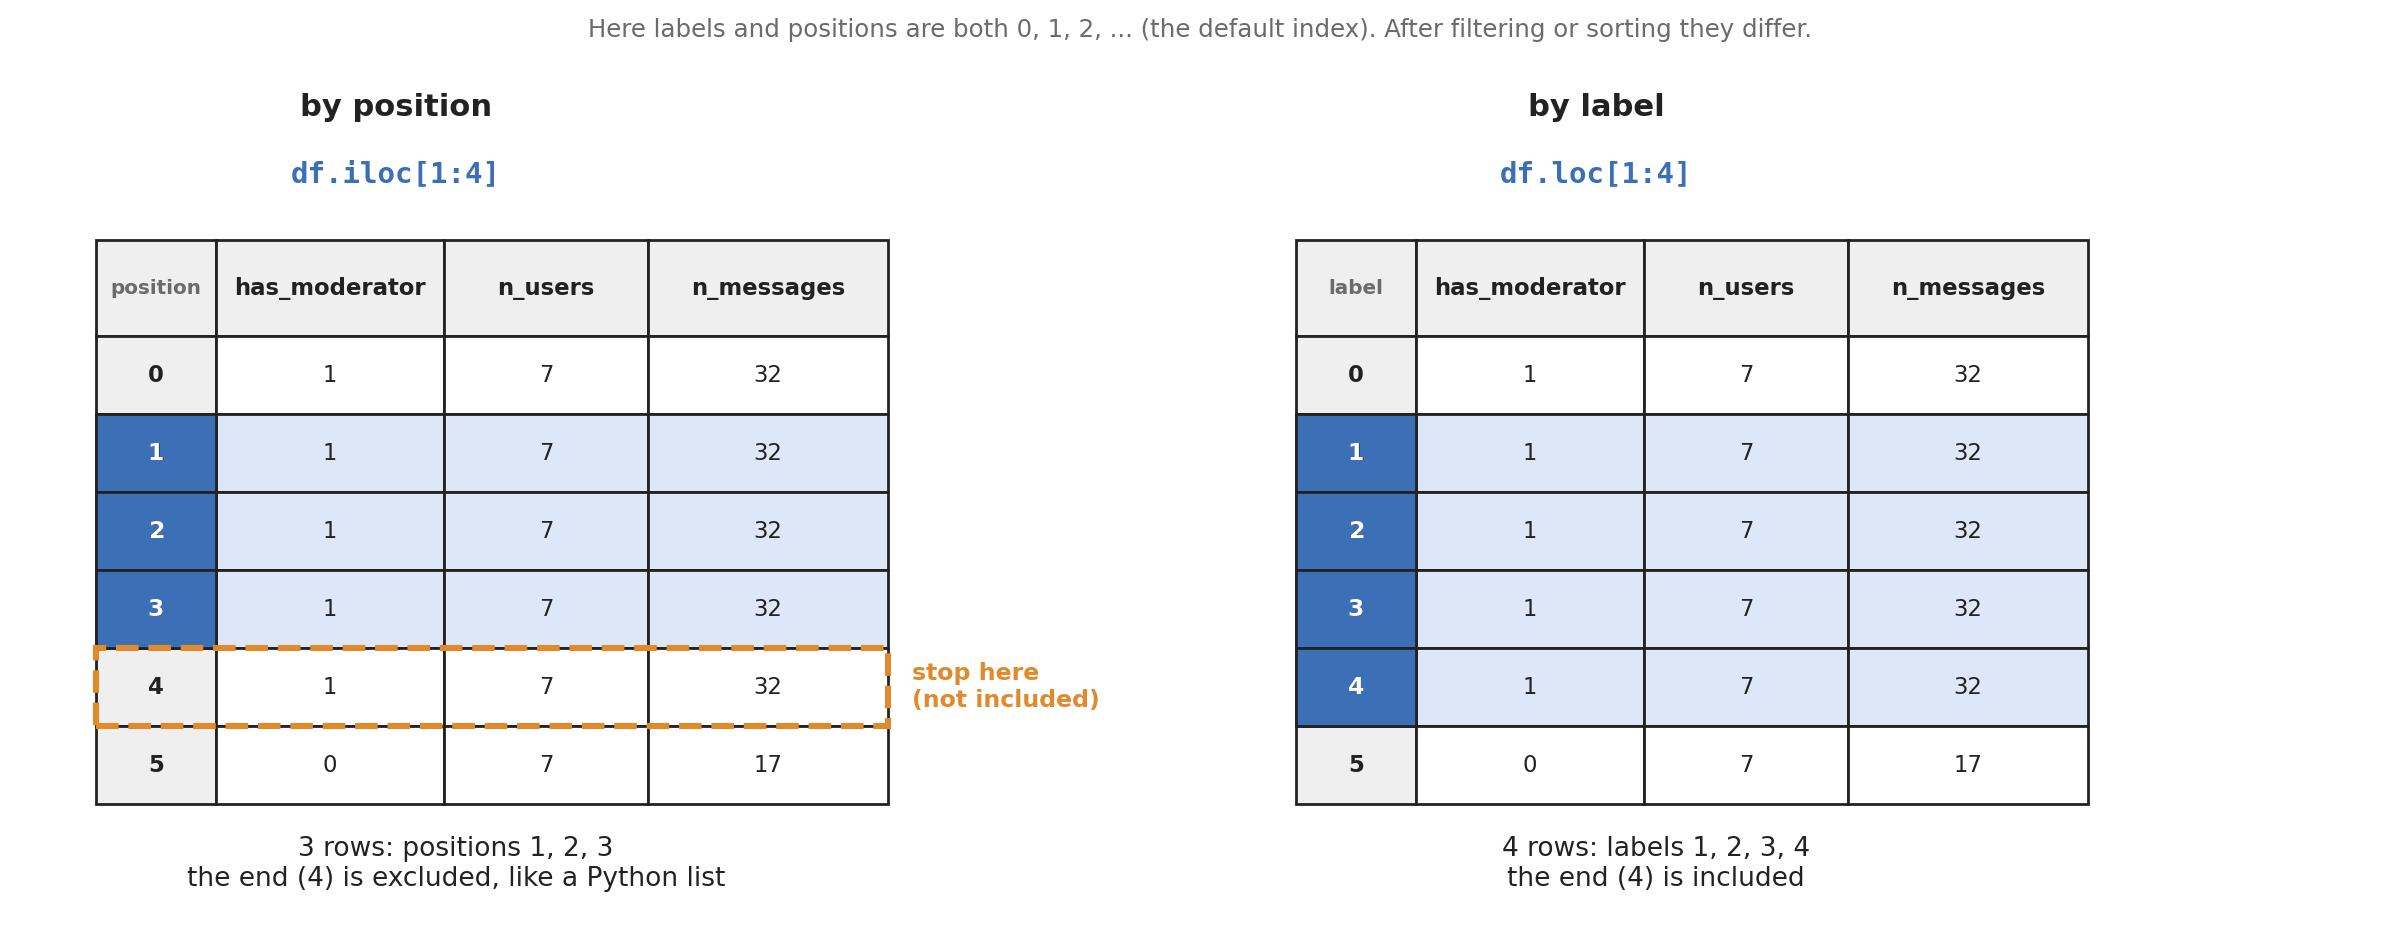

In [16]:
# the same-looking slice, with different ends: iloc excludes the end, loc includes it
print("iloc[10:15] gives", len(summary.iloc[10:15]), "rows (positions 10 to 14)")
print("loc[10:15]  gives", len(summary.loc[10:15]), "rows (labels 10 to 15)")

# rows and columns together: by label, and by position (the same cells)
by_label = summary.loc[10:14, ["experiment", "n_messages"]]
by_position = summary.iloc[10:15, [0, 3]]
print("same cells:", by_label.equals(by_position))


iloc[10:15] gives 5 rows (positions 10 to 14)
loc[10:15]  gives 6 rows (labels 10 to 15)
same cells: True


If we make `experiment` the row labels (the index), we can select a whole folder by its name. A range of labels needs a **sorted** index.

In [17]:
# experiment becomes the row labels (the index); a range of labels needs it sorted
by_cond = summary.set_index("experiment").sort_index()

# one label selects every row with that label: all 30 conversations of the folder
nomod = by_cond.loc["llama8b_nomod", "n_messages"]
print(len(nomod), "conversations in llama8b_nomod, all with", nomod.unique(), "messages")

# a range of labels (both ends included) and a list of columns
by_cond.loc["llama70b_vanilla.txt":"llama8b_erulemaking.txt", ["n_messages", "n_mod_messages"]].shape

30 conversations in llama8b_nomod, all with [17] messages


(90, 2)

The experiment fixed the length: moderated conversations have 32 messages, `nomod` ones 17. The real variation is **inside the messages**.

### 2.3 One row per message

`explode` gives every message its own row. Each message is still a dict, so we pick its keys out with `.str[...]`. The result, `msgs`, is the main table for the rest of the lab.

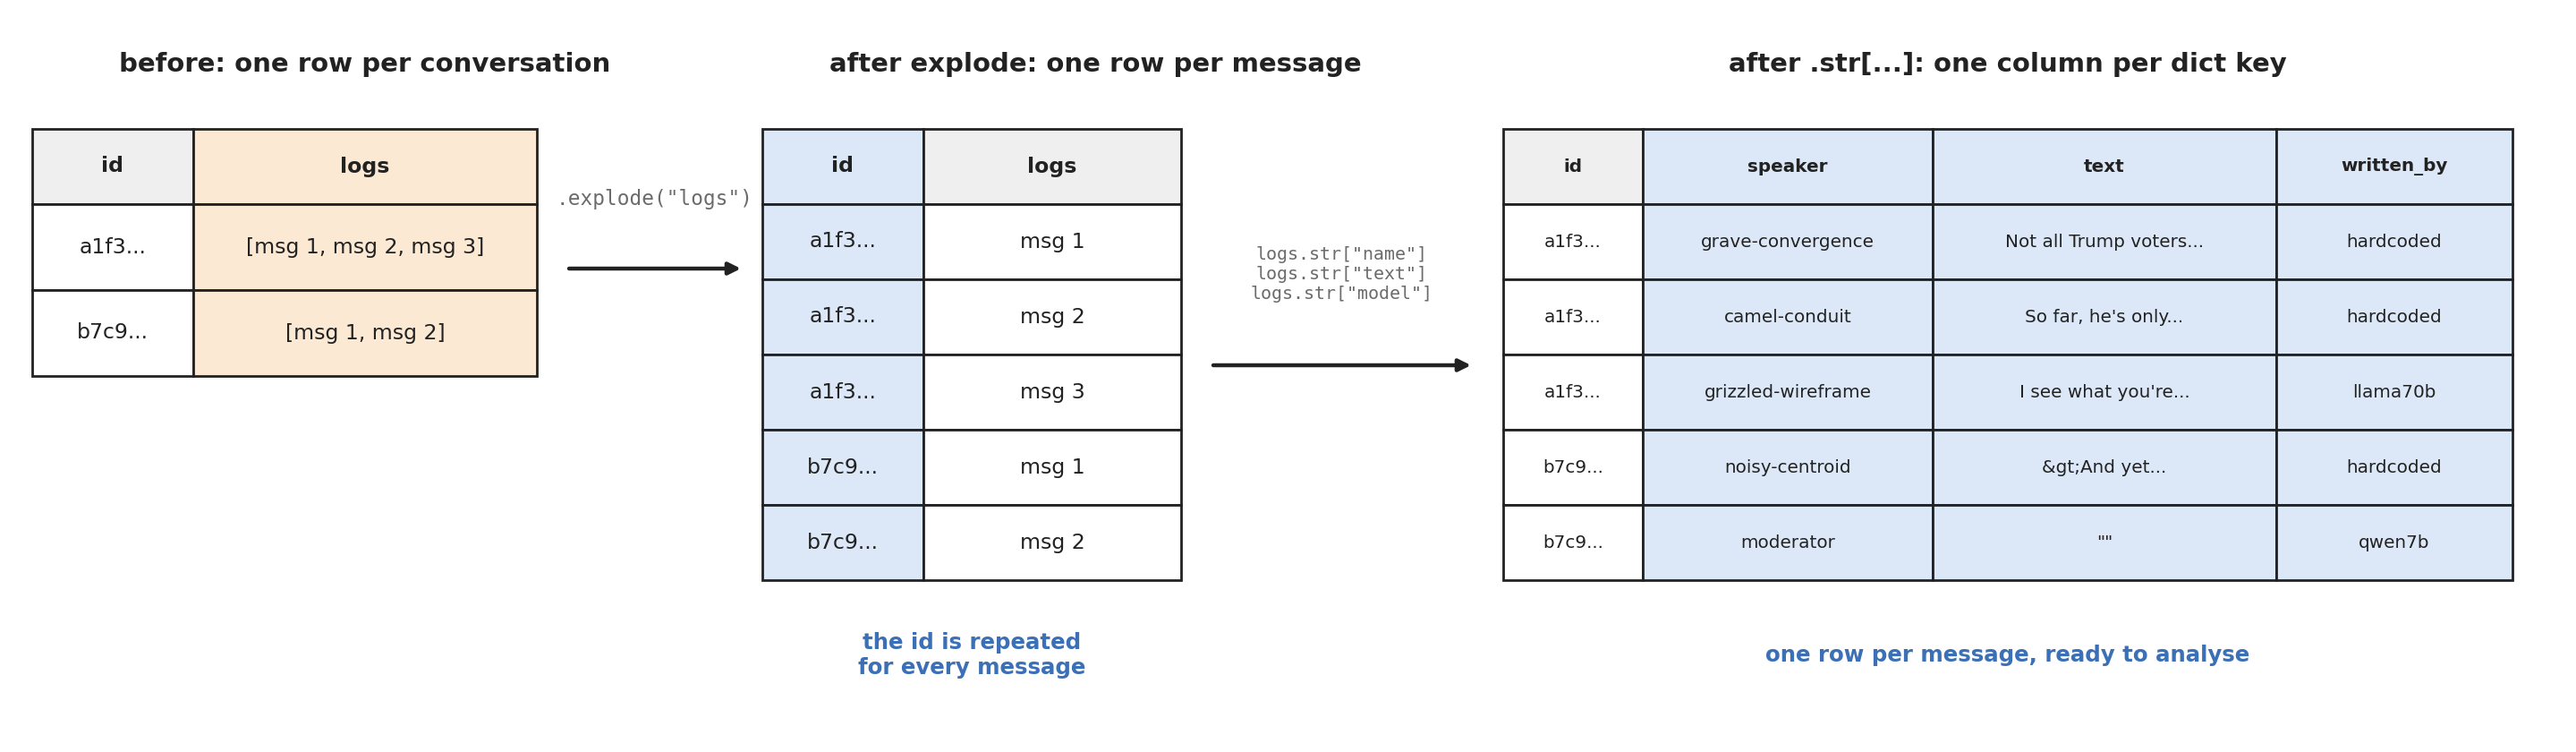

In [18]:
# explode: one row per item of the list in `logs`; the other columns are repeated
msgs = df[["id", "experiment", "has_moderator", "logs"]].explode("logs", ignore_index=True)

# every message is a dict: .str[key] picks one key out of every dict
msgs["speaker"] = msgs["logs"].str["name"]
msgs["text"] = msgs["logs"].str["text"]
msgs["written_by"] = msgs["logs"].str["model"]
# the dicts are no longer needed; id is renamed to say what it identifies
msgs = msgs.drop(columns="logs").rename(columns={"id": "conv_id"})

# a number for every message: its length in characters
msgs["n_chars"] = msgs["text"].str.len()
print(f"{len(msgs)} messages from {len(df)} conversations")
msgs["n_chars"].describe().round(2)

20340 messages from 720 conversations


count    20340.00
mean       339.09
std        278.67
min          2.00
25%        206.00
50%        315.00
75%        451.00
max       7483.00
Name: n_chars, dtype: float64

In [19]:
df[["id", "experiment", "has_moderator", "logs"]].head()

,id,experiment,has_moderator,logs
0,1327e2a5-f931-4212-a1d9-b3efb7fb5348,llama70b_constructive_communications.txt,1,"[{'name': 'grave-convergence', 'text': 'Not al..."
1,b3805d66-7317-44c0-99d8-d724b85d97ed,llama70b_constructive_communications.txt,1,"[{'name': 'noisy-centroid', 'text': '&gt;And y..."
2,70da56c7-4b0d-4b19-823f-1b6914dc6ffa,llama70b_constructive_communications.txt,1,"[{'name': 'exothermic-poset', 'text': 'You can..."
3,56ff988c-0318-41d9-b83e-89110871dd36,llama70b_constructive_communications.txt,1,"[{'name': 'shortest-child', 'text': 'I will tr..."
4,07ad40d6-2364-4f65-bbcb-af30f253b0d9,llama70b_constructive_communications.txt,1,"[{'name': 'rank-ambiance', 'text': 'Men have h..."


In [20]:
msgs.head()

,conv_id,experiment,has_moderator,speaker,text,written_by,n_chars
0,1327e2a5-f931-4212-a1d9-b3efb7fb5348,llama70b_constructive_communications.txt,1,grave-convergence,Not all Trump voters do it based out of hate a...,hardcoded,500
1,1327e2a5-f931-4212-a1d9-b3efb7fb5348,llama70b_constructive_communications.txt,1,camel-conduit,"So far, he's only showed that he can get atten...",hardcoded,349
2,1327e2a5-f931-4212-a1d9-b3efb7fb5348,llama70b_constructive_communications.txt,1,grizzled-wireframe,"""I see what you're saying, @grave-convergence,...",llama70b,402
3,1327e2a5-f931-4212-a1d9-b3efb7fb5348,llama70b_constructive_communications.txt,1,moderator,"""Let's keep the discussion focused on the topi...",llama70b,194
4,1327e2a5-f931-4212-a1d9-b3efb7fb5348,llama70b_constructive_communications.txt,1,loyal-pool,"""I completely agree with @grizzled-wireframe. ...",llama70b,455


### 2.4 Statistics on message length

The mean (339) is above the median (315): a few very long messages pull it up. The mode is the spike of the shortest messages at the far left.

mean 339.1 | median 315.0 | mode 2 | std 278.7


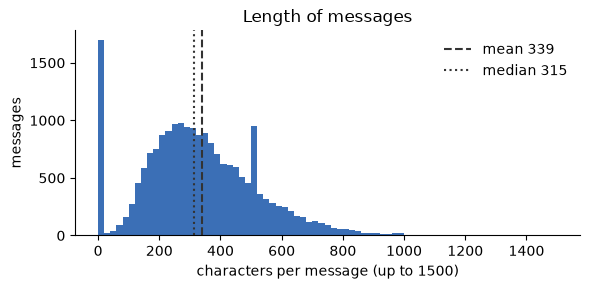

In [21]:
chars = msgs["n_chars"]
print("mean", round(chars.mean(), 1), "| median", chars.median(), "| mode", chars.mode()[0], "| std", round(chars.std(), 1))

# histogram of the lengths; range=(0, 1500) hides the few huge messages so the shape is visible
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(chars, bins=75, range=(0, 1500), color="#3b6fb6")
# the dashed and dotted lines mark the mean and the median
ax.axvline(chars.mean(), color="#333333", linestyle="--", label=f"mean {chars.mean():.0f}")
ax.axvline(chars.median(), color="#333333", linestyle=":", label=f"median {chars.median():.0f}")
ax.set_xlabel("characters per message (up to 1500)")
ax.set_ylabel("messages")
ax.set_title("Length of messages")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Look at the extremes.** `idxmin` and `idxmax` return the row label of the smallest and the largest value, so we can read the actual messages. `value_counts` also works on text: who speaks the most?

In [22]:
# idxmin / idxmax: the row label of the smallest / largest value, so we can read that message
for name, label in [("shortest", chars.idxmin()), ("longest", chars.idxmax())]:
    print(name, "|", chars[label], "characters |", repr(msgs.loc[label, "text"][:70]))


shortest | 2 characters | '""'
longest | 7483 characters | '""\n``` @strong-limousine, thank you for your supportive response. It\'s'


In [23]:
print("\nmessages per speaker (the three most active):")
# normalize=True gives shares instead of counts
msgs["speaker"].value_counts(normalize=True).head(3)


messages per speaker (the three most active):


speaker
moderator         0.398230
quiet-right       0.001278
gilded-grantor    0.001278
Name: proportion, dtype: float64

The shortest message is an empty `""`, and the longest is thousands of characters long. And **one speaker, the moderator, writes 40% of all messages.**

### 2.5 Do all seven users speak?

Every conversation has 7 users, so we expect 7 speakers. To check, we count the different names in each `logs` list (a set keeps every name once), leaving out the moderator, and count how many messages each user writes.

users who speak, per conversation:
logs
7    494
6    209
5     17

messages per user in a conversation:
count    4797.0
mean        2.6
std         1.2
min         1.0
25%         2.0
50%         2.0
75%         3.0
max         8.0

different speaker names in the whole table: 1880


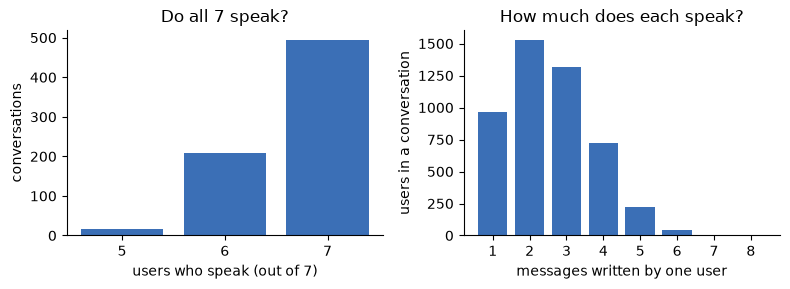

In [24]:
# for each conversation: the set of speaker names (a set keeps each name once), minus the moderator, counted
n_speakers = df["logs"].apply(lambda msgs: len({m["name"] for m in msgs} - {"moderator"}))
print("users who speak, per conversation:")
print(n_speakers.value_counts().to_string())

# value_counts on two columns counts the messages of each (conversation, speaker) pair
users_only = msgs[msgs["speaker"] != "moderator"]
print("\nmessages per user in a conversation:")
print(users_only.value_counts(["conv_id", "speaker"]).describe().round(1).to_string())
print("\ndifferent speaker names in the whole table:", msgs["speaker"].nunique())

# left: how many of the 7 users speak; right: how many messages each user writes
per_user = users_only.value_counts(["conv_id", "speaker"])
speakers_count = n_speakers.value_counts().sort_index()
messages_count = per_user.value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.bar(speakers_count.index.astype(str), speakers_count.values, color="#3b6fb6")
ax1.set_xlabel("users who speak (out of 7)")
ax1.set_ylabel("conversations")
ax1.set_title("Do all 7 speak?")
ax2.bar(messages_count.index.astype(str), messages_count.values, color="#3b6fb6")
ax2.set_xlabel("messages written by one user")
ax2.set_ylabel("users in a conversation")
ax2.set_title("How much does each speak?")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The charts show it. Only 69% of the conversations have all 7 users speaking; in the others 5 or 6 do. Those who speak write 2 or 3 messages each (mean 2.6), but some write only 1 and some up to 8. The table also holds far fewer names (about 1,900) than the 5,040 user slots (720 × 7): **the same name appears in several conversations**, so a name is not one person we can follow through the data. Count speakers inside a conversation, not across the table. Before building on these values we have to look at them: Part 3 does.

### 2.6 Changing values

`replace` swaps one value for another, `map` applies a dictionary, and `clip` caps the extremes.

In [25]:
# replace: the opening comments come from real data, not from a model
msgs["written_by"] = msgs["written_by"].replace("hardcoded", "real comment")

# map: 0/1 becomes a readable label
msgs["has_moderator"] = msgs["has_moderator"].map({0: "no", 1: "yes"})

# clip: cap the extremes at 1000 characters; the mean barely moves, the std and max change a lot
msgs["n_chars_capped"] = msgs["n_chars"].clip(upper=1000)

print(msgs["written_by"].value_counts().to_string())

# how many messages did clip change? those longer than the cap
n_clipped = (msgs["n_chars"] > 1000).sum()
print(f"\n{n_clipped} messages ({n_clipped / len(msgs):.1%}) were longer than 1000 characters and were capped")
msgs[["n_chars", "n_chars_capped"]].agg(["mean", "std", "max"]).round(1)

written_by
llama70b        3150
llama8b         3150
mistral24b      3150
qwen32b         3150
mistral7b       3150
qwen7b          3150
real comment    1440

102 messages (0.5%) were longer than 1000 characters and were capped


,n_chars,n_chars_capped
mean,339.1,332.1
std,278.7,192.1
max,7483.0,1000.0


**Your turn.** What is the 99th percentile of `n_chars` (use `quantile`), and how many messages are longer than it?

In [26]:
# your code here

<details><summary>Solution</summary>

```python
p99 = msgs["n_chars"].quantile(0.99)
print(p99, (msgs["n_chars"] > p99).sum())
```

</details>

### Findings: Part 2

- `iloc` selects by position and excludes the end; `loc` selects by label and includes it; label slices need a sorted index.
- Conversation length is fixed by the design (32 or 17 messages). The variation is inside the messages, so we flattened `logs` into `msgs`: 20,340 rows.
- Message length is right-skewed: the mean is above the median, with a long tail up to about 7,500 characters.
- Not every user speaks: all 7 do in 69% of the conversations. Names repeat across conversations, so we count speakers within one conversation.
- The moderator writes 8,100 of the 20,340 messages (40%), and the shortest message is an empty `""`.
- `replace`, `map` and `clip` change values without changing the structure of the table.

## Part 3 · Filtering and cleaning text

> **Goal.** Select rows with conditions, work with the text inside a column, and prepare it for analysis.
>
> **The story.** Part 2 ended with a puzzle: the shortest message is an empty `""`. Is it a rare glitch, or a pattern? We find out who writes these messages, then clean the text so that the messages can be compared.

### 3.1 A condition gives a mask

A comparison on a whole column gives a `True`/`False` for every row, called a **mask**. Putting the mask in `[ ]` keeps only the `True` rows.

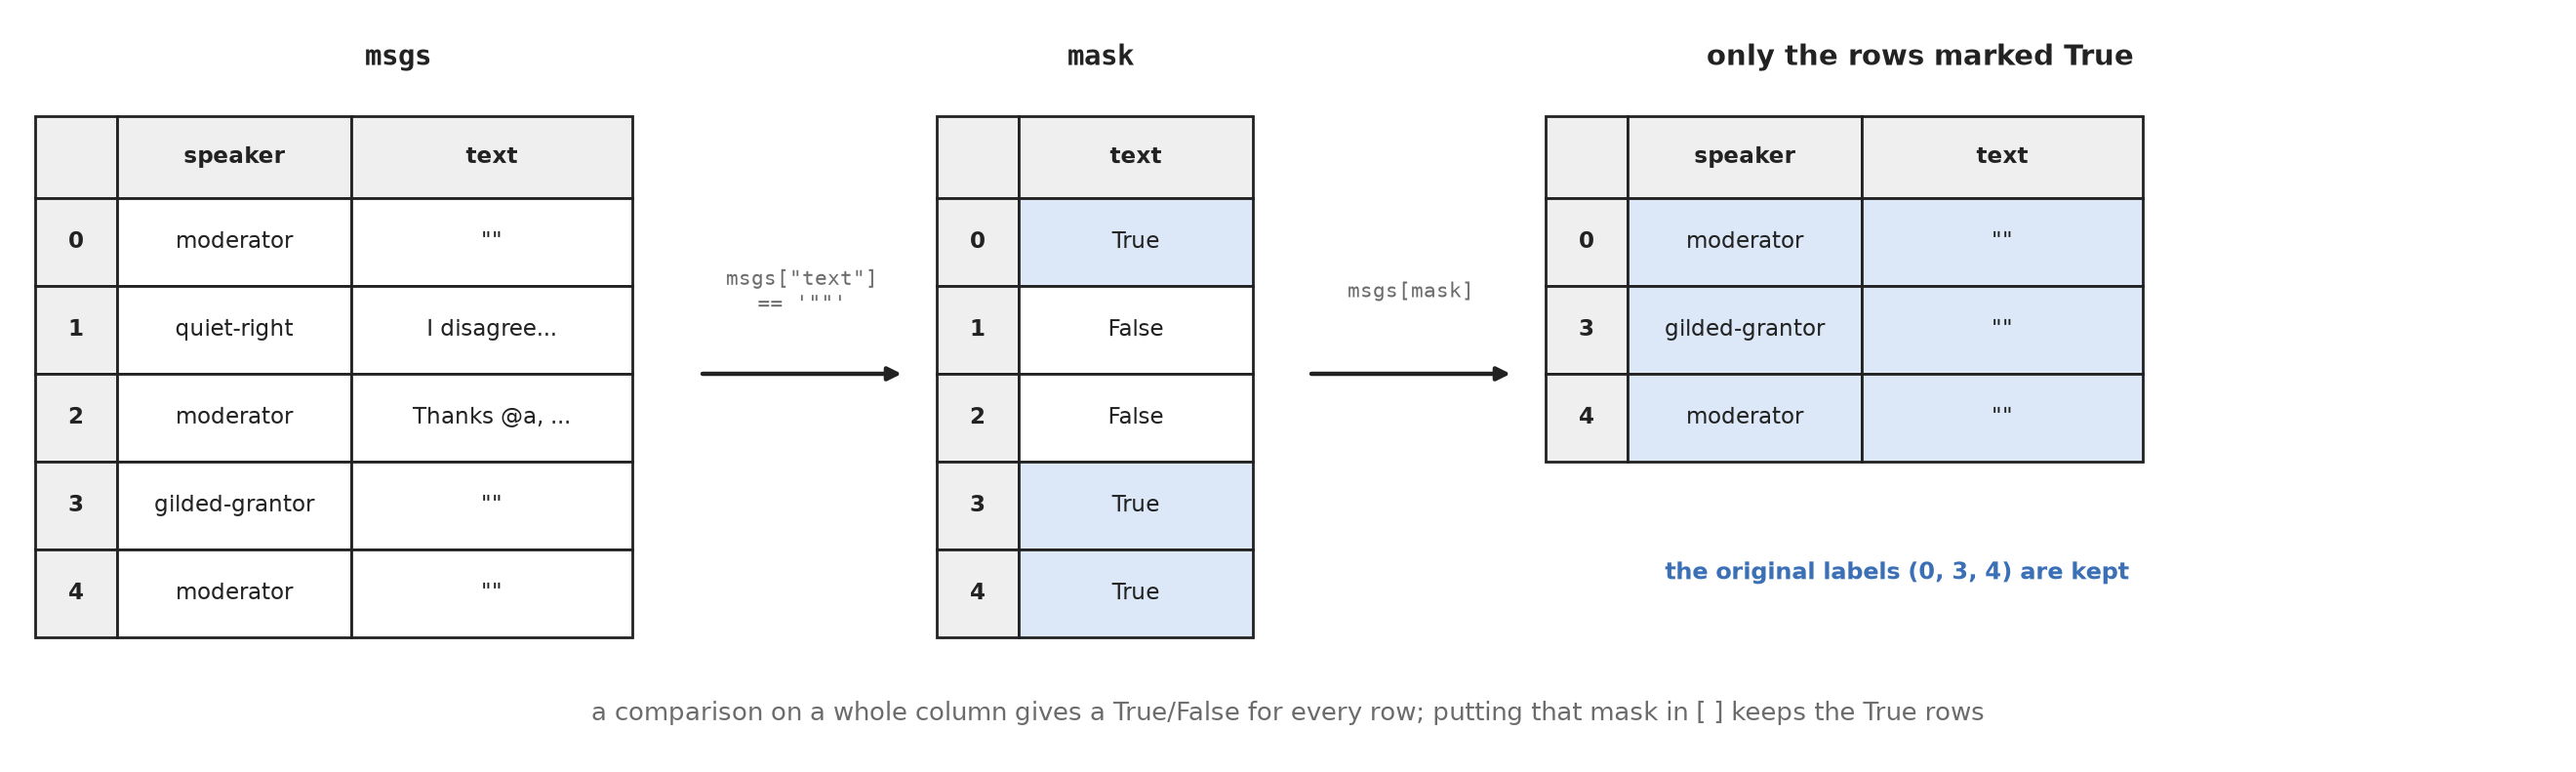

In [27]:
# a comparison on a whole column gives True/False for every row: a mask
is_empty = msgs["text"] == '""'
is_mod = msgs["speaker"] == "moderator"
# a whole True/False column gives one result: sum() counts the True values, mean() is their share (True = 1, False = 0)
print(f"{is_empty.sum()} empty messages, {is_empty.mean():.1%} of all")
# loc with a mask and a list of columns: only those rows, only those columns
msgs.loc[is_empty, ["speaker", "written_by", "text"]].head(3)

1682 empty messages, 8.3% of all


,speaker,written_by,text
25,moderator,llama70b,""""""
27,moderator,llama70b,""""""
107,moderator,llama70b,""""""


Join masks with `&` (and), `|` (or) and `~` (not), with **parentheses** around every comparison. `isin` tests membership in a list and `between` tests a range. The silent messages are mostly the moderator's: it is allowed to say nothing. Which model is silent? We divide two `value_counts`: the share of silent messages among each model's moderator messages (dividing two Series lines them up by label).

empty moderator messages: 1390 of 8100
empty user messages:      292 of 12240


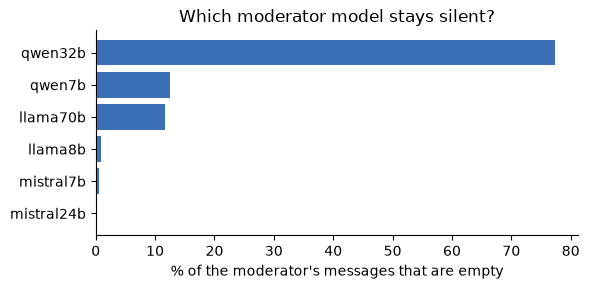

In [28]:
# & combines two masks (and), ~ flips a mask (not)
print("empty moderator messages:", (is_empty & is_mod).sum(), "of", is_mod.sum())
print("empty user messages:     ", (is_empty & ~is_mod).sum(), "of", (~is_mod).sum())

mod = msgs[is_mod]
silent = mod[mod["text"] == '""']
# silent messages per model / all moderator messages per model (divided by label); no silent message -> NaN -> 0
silent_share = (silent["written_by"].value_counts() / mod["written_by"].value_counts()).fillna(0)
silent_share = (silent_share * 100).sort_values()

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(silent_share.index, silent_share.values, color="#3b6fb6")
ax.set_xlabel("% of the moderator's messages that are empty")
ax.set_title("Which moderator model stays silent?")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Silence is a property of **one model**: `qwen32b` says nothing in about three of every four turns, while `mistral24b` always answers. An empty message should not count as a moderator turn, so we drop those rows.

`drop` removes rows (by label) or columns and returns a new table. `pop` removes **one column in place** and returns it. After dropping rows the labels have gaps, so `reset_index(drop=True)` makes labels and positions agree again.

In [29]:
print("before:", msgs.shape)

# drop removes rows by label; reset_index(drop=True) renumbers 0, 1, 2... because the old labels have gaps
empty_labels = msgs[msgs["text"] == '""'].index
msgs = msgs.drop(index=empty_labels).reset_index(drop=True)
capped = msgs.pop("n_chars_capped")      # not needed any more

print("after: ", msgs.shape)

before: (20340, 8)
after:  (18658, 7)


### 3.2 Working with the text

The `.str` methods work on every row at once: `.str[:n]` slices, `startswith` and `contains` give masks, and `contains` and `extract` accept a **regular expression** (regex), a pattern such as `@[\w-]+` for "an @ followed by letters, digits or `-`".

In [30]:
# many texts are wrapped in quotation marks by the model: how many, per writer?
quoted = msgs["text"].str.startswith('"')
# share of each writer's messages that start with a quote: (quoted per writer) / (all per writer)
quote_share = (msgs.loc[quoted, "written_by"].value_counts() / msgs["written_by"].value_counts()).fillna(0)
print(f"{quoted.sum()} of {len(msgs)} messages start with a quote")

# the same, per writer, as a percentage of that writer's own messages
print("\n% of each writer's messages that start with a quote:")
print((quote_share * 100).round(0).sort_values(ascending=False).astype(int).astype(str).add("%").to_string())

11517 of 18658 messages start with a quote

% of each writer's messages that start with a quote:
written_by
mistral7b       95%
llama70b        92%
qwen32b         81%
llama8b         80%
qwen7b          60%
real comment     1%
mistral24b       0%


In [31]:
# regex: who is mentioned with @name?
# @ followed by one or more letters, digits or '-'
has_mention = msgs["text"].str.contains(r"@[\w-]+")
# extract returns what is inside the ( ) of the pattern: the name without the @
first_mention = msgs["text"].str.extract(r"@([\w-]+)")[0]
print(f"{has_mention.sum()} messages contain an @mention; the most mentioned name:")
print(first_mention.value_counts().head(2).to_string())

15199 messages contain an @mention; the most mentioned name:
0
moderator      2124
salty-truck      47


Quotes depend on the model and mentions are part of the text. Both distort a word count, so we clean the text in a **chain**: every step is a `.str` method applied to the result of the one before. First, operations between columns work row by row: `n_chars / n_words` divides each row's value by its own.

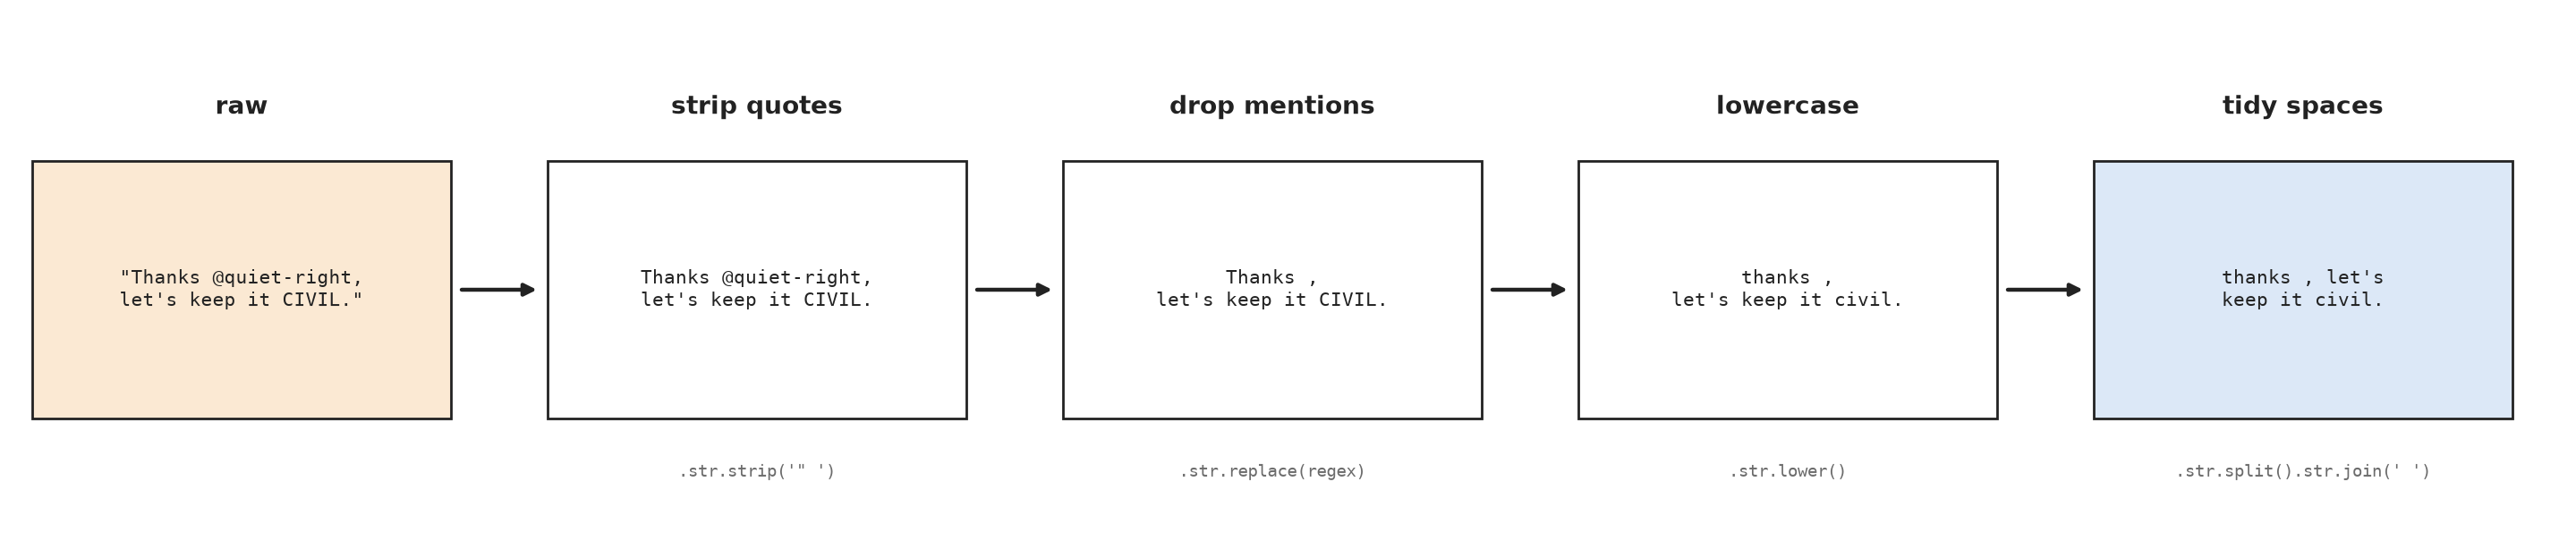

In [32]:
msgs["is_mod"] = msgs["speaker"] == "moderator"
# split() cuts a text on spaces: counting the pieces counts the words
msgs["n_words"] = msgs["text"].str.split().str.len()
# arithmetic between two columns works row by row
msgs["chars_per_word"] = (msgs["n_chars"] / msgs["n_words"]).round(2)

Now the cleaning chain. Each line is one `.str` step applied to the result of the one before, as in the figure above. The result goes into a new column, `clean_text`; `text` stays as it was. `n_words_clean` counts the words again, this time on the clean text.

In [33]:
# a chain: every step works on the result of the one before
msgs["clean_text"] = (
    msgs["text"]
    .str.replace("```", " ", regex=False)       # a few models also add code fences
    .str.strip('" \n')                           # quotes and spaces at both ends
    .str.replace(r"@[\w-]+", "", regex=True)     # drop the @mentions
    .str.lower()                                 # THE and the become the same word
    .str.split().str.join(" ")                   # any run of spaces or line breaks -> one space
)
msgs["n_words_clean"] = msgs["clean_text"].str.split().str.len()

**Check the result before using it.** We read one message before and after, count the messages the cleaning left empty, and compare the word counts.

In [34]:
print("before:", repr(msgs.loc[4, "text"][:90]))
print("after: ", repr(msgs.loc[4, "clean_text"][:90]))
print("\nmessages left empty by the cleaning:", (msgs["clean_text"] == "").sum(), "of", len(msgs))
print("mean words, raw vs clean:", round(msgs["n_words"].mean(), 1), "vs", round(msgs["n_words_clean"].mean(), 1))
print("mean words, moderator:", round(msgs.loc[msgs["is_mod"], "n_words_clean"].mean(), 1),
      "| users:", round(msgs.loc[~msgs["is_mod"], "n_words_clean"].mean(), 1))

before: '"I completely agree with @grizzled-wireframe. The way he presents his policies is not only'
after:  "i completely agree with . the way he presents his policies is not only divisive, but it's "

messages left empty by the cleaning: 2 of 18658
mean words, raw vs clean: 58.8 vs 58.3
mean words, moderator: 44.4 | users: 66.1


**Your turn.** How many messages mention `@moderator`, and how many of those are written by users? (hint: `contains` gives a mask, combine it with `~msgs["is_mod"]`.)

In [35]:
# your code here

<details><summary>Solution</summary>

```python
m = msgs["text"].str.contains("@moderator")
print(m.sum(), (m & ~msgs["is_mod"]).sum())
```

</details>

### Findings: Part 3

- A comparison makes a mask; `&`, `|`, `~`, `isin` and `between` combine and extend it; `msgs[mask]` keeps the `True` rows.
- 1,682 messages (8%) were empty `""`, 83% of them the moderator's, and mostly from one model, `qwen32b`. We dropped them: 18,658 messages are left.
- `.str` slicing, `startswith`, `contains` and regex `extract` turn text into masks and new columns. Many texts are wrapped in quotes and 81% mention someone.
- Text cleaning is a chain of small `.str` steps, and we check the result afterwards: 2 messages were only mentions and are now empty. Moderators write shorter messages than users (44 against 66 words).
- `msgs` now has `clean_text` and `n_words_clean`.

## Part 4 · Dates and times

> **Goal.** Get parts out of a date, filter by date, and measure the time between rows.
>
> **The story.** The conversations are synthetic, but they took real time to generate: the `timestamp` of each file tells us when it was created. How long did the experiment run, and how long does one conversation take?

### 4.1 Parts of a date

The `timestamp` has been a real datetime since Part 1, so `min` and `max` work, and subtracting two datetimes gives a **Timedelta**. The `.dt` accessor (like `.str` for text) gives the parts of every date at once.

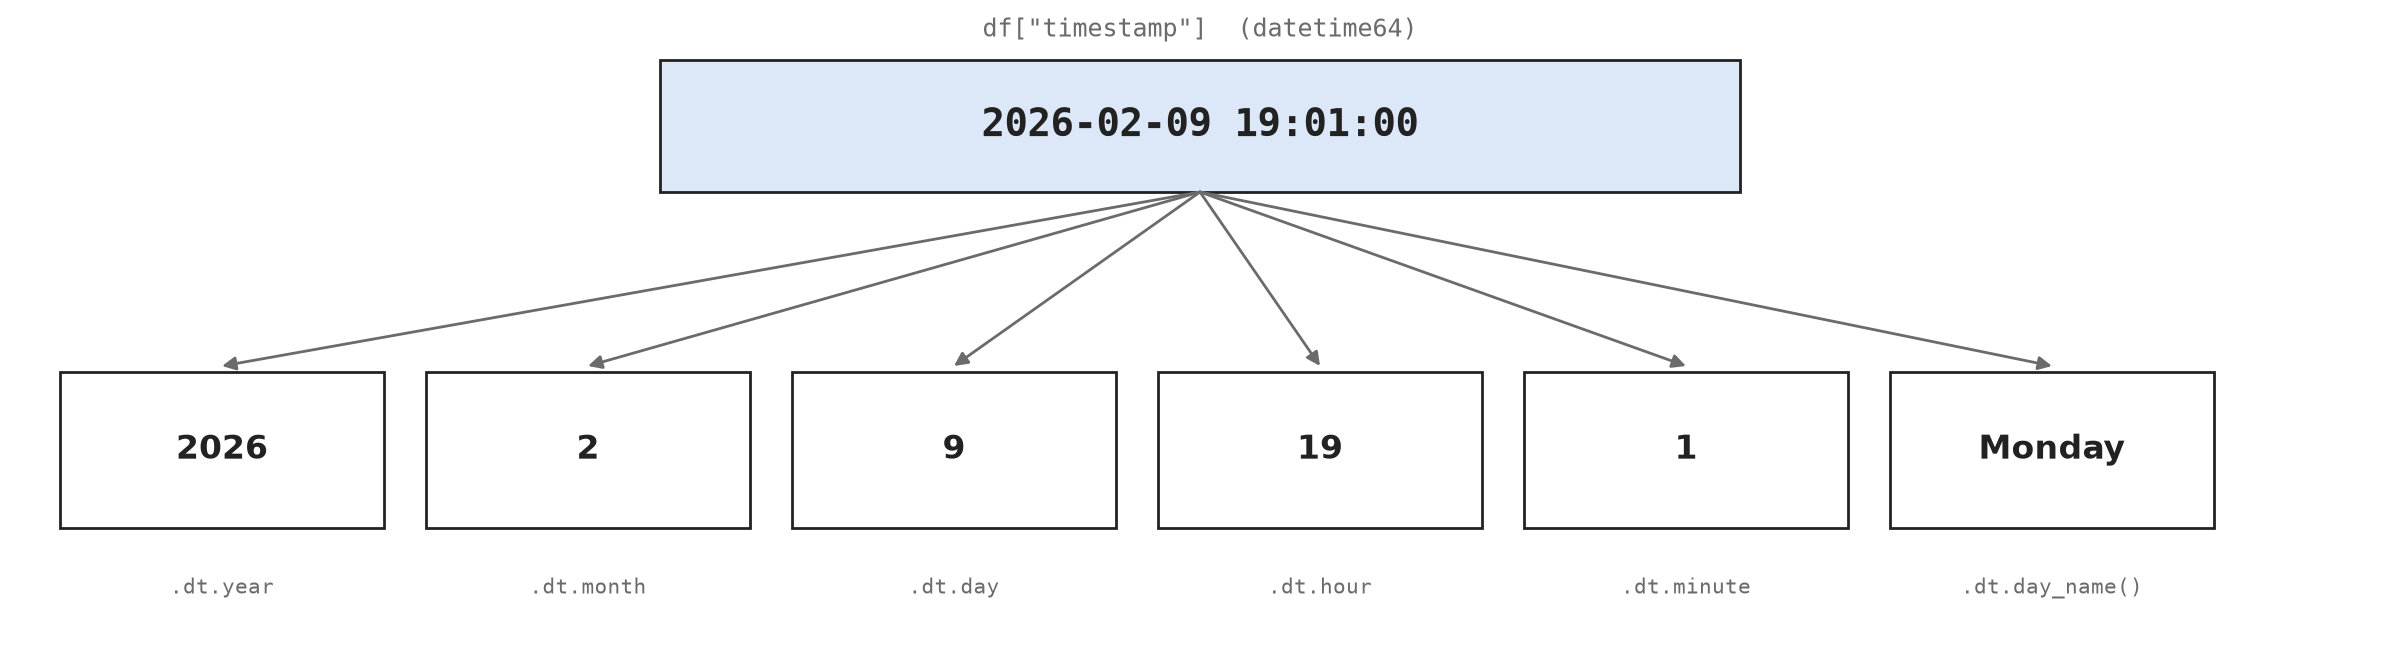

from 2026-02-09 19:01:00 to 2026-02-22 14:26:00 -> 12 days and 19 hours


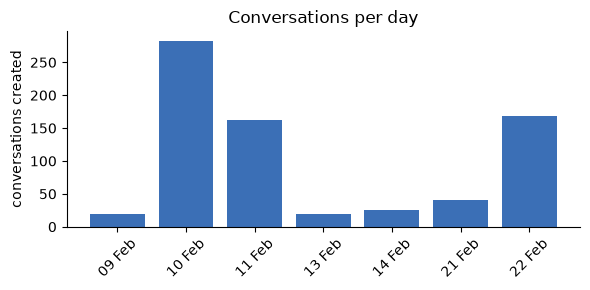

In [36]:
t = df["timestamp"]
# the difference of two datetimes is a Timedelta, a length of time
span = t.max() - t.min()
print("from", t.min(), "to", t.max(), "->", span.days, "days and", span.seconds // 3600, "hours")

# conversations per day: the experiment did not run evenly
# .dt gives the parts of a date; .dt.date keeps only the day
per_day = t.dt.date.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar([d.strftime("%d %b") for d in per_day.index], per_day.values, color="#3b6fb6")
ax.set_ylabel("conversations created")
ax.set_title("Conversations per day")
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Three bursts, 9-11, 13-14 and 21-22 February, and nothing in between. A date written as text can be used in a comparison, as in Part 3.

### 4.2 Time between rows

`diff` subtracts every row from the previous one, so on a datetime column it gives the time between consecutive conversations. The table is ordered by folder, so we take one folder, created one conversation after another. `.dt.total_seconds()` turns a Timedelta into a number.

In [37]:
# a date written as text can be compared with a datetime column
print((df["timestamp"] >= "2026-02-21").sum(), "conversations were created from 21 February on")

# only the rows of one folder: they were created one after the other
one = df.loc[df["experiment"] == "llama8b_nomod", "timestamp"]
# diff: each value minus the previous one, so the time between consecutive conversations
gap_min = one.diff().dt.total_seconds() / 60    # minutes since the previous conversation

print("\nminutes between consecutive conversations of llama8b_nomod:")
print("  median:", gap_min.median(), "| mean:", round(gap_min.mean(), 1), "| max:", gap_min.max())

210 conversations were created from 21 February on

minutes between consecutive conversations of llama8b_nomod:
  median: 3.0 | mean: 547.4 | max: 15790.0


The numbers are in minutes. The median says that one conversation takes **about 3 minutes**. The mean (547 minutes, about 9 hours) describes no conversation at all: it is pulled up by one huge value, the maximum, a pause of 15,790 minutes (about 11 days) between two bursts. Without that one gap the mean would be about 3 minutes too.

**A few very large values pull the mean up, but barely move the median.** The mean adds up every value, so one extreme value shifts it a lot. The median only looks at the middle of the sorted values, so it ignores how large the extremes are. This is the same lesson as the mean above the median in Part 2: when the data has outliers, the median describes the typical value better. We use the median.

**Your turn.** On which weekday were most conversations created? (hint: `.dt.day_name()`, then `value_counts`.)

In [38]:
# your code here

<details><summary>Solution</summary>

```python
df["timestamp"].dt.day_name().value_counts()
```

</details>

### Findings: Part 4

- Subtracting two datetimes gives a Timedelta; `.dt.total_seconds()` turns it into a number; `.dt` gives the parts of a date.
- The experiment spanned 12 days but ran in three bursts.
- A conversation takes about 3 minutes in one folder. Part 5 asks whether that is the same for every model.

## Part 5 · Groups and joins

> **Goal.** Compute a statistic for every group, stack tables, and bring a column from one table into another.
>
> **The story.** Do bigger models need more time? And do users write differently when a moderator is present? The first needs the folder name split into a `model` and a `setting`; the second needs the setting inside the messages table, so we join the two tables.

### 5.1 `groupby`

`groupby` splits the table into one small table per value of a column, applies a function to each (here the median), and combines the results into one Series. We first split the folder name (`<model>_<setting>`, like `qwen7b_vanilla.txt`) with `.str`, and compute the time since the previous conversation *inside each folder*.

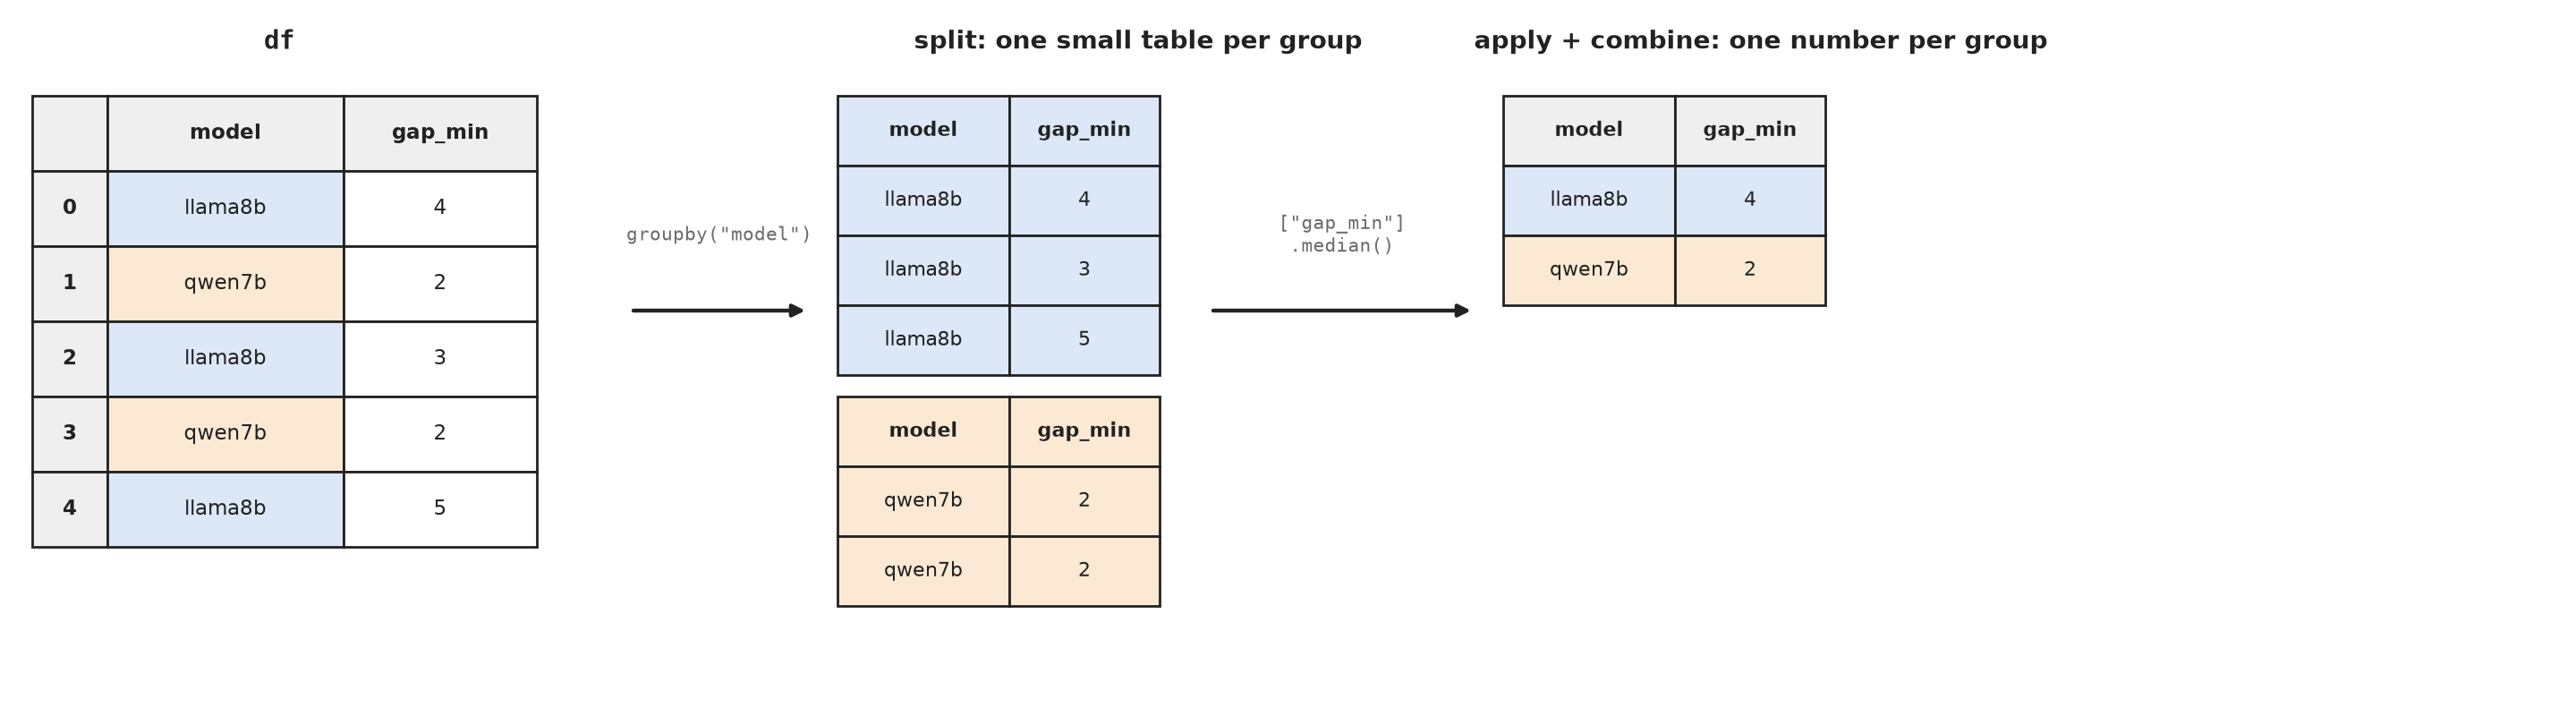

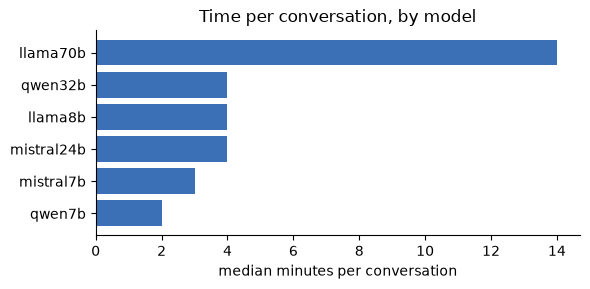

In [39]:
# split at the first _ only: two pieces, the model and the setting
parts = df["experiment"].str.split("_", n=1)             # "qwen7b_vanilla.txt" -> ["qwen7b", "vanilla.txt"]
df["model"] = parts.str[0]
# the second piece is the setting; the folders end in ".txt", except the nomod ones
df["setting"] = parts.str[1].str.replace(".txt", "", regex=False)

# groupby makes diff work inside each folder, not across two folders
# (a folder's first conversation has no previous one: NaN)
df["gap_min"] = df.groupby("experiment")["timestamp"].diff().dt.total_seconds() / 60

# groupby: split by model, take the median of gap_min in each group, combine into one Series
gap_by_model = df.groupby("model")["gap_min"].median().sort_values()

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(gap_by_model.index, gap_by_model.values, color="#3b6fb6")
ax.set_xlabel("median minutes per conversation")
ax.set_title("Time per conversation, by model")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

`llama70b` needs about 14 minutes per conversation, the others between 2 and 4: the largest model is by far the slowest. `agg` computes several statistics at once, and `groupby` accepts a list of columns to group by more than one.

### 5.2 `concat`

`pd.concat` glues tables together, in one of two directions:

- **One under the other** (the default, `axis=0`). Use it when the tables have **the same columns**, for example two parts of the same table. The columns are matched by name, so their order does not matter. If a column exists in only one table, the rows of the other get `NaN` there. The rows keep their original labels (add `ignore_index=True` to renumber them 0, 1, 2...).
- **Side by side** (`axis=1`). Use it when the tables describe **the same rows**, for example two summaries with the same index. The rows are matched by their **labels** (the index), not by position. A label that is in only one table gets `NaN` in the columns of the other.

The tables are only glued together, nothing is looked up. To bring in columns by a value they share, such as an id, we use `merge` (next).

In [40]:
# one under the other: split the messages in two and put them back together
mod_rows = msgs[msgs["is_mod"]]
usr_rows = msgs[~msgs["is_mod"]]
back = pd.concat([mod_rows, usr_rows])

print(len(mod_rows), "moderator rows +", len(usr_rows), "user rows")
print("rows in the original table:", len(msgs), "| rows after concat:", len(back))

# side by side: mean words per message for the moderator and for the users, one row per writer
# groupby: one mean per writer
mod_words = msgs[msgs["is_mod"]].groupby("written_by")["n_words_clean"].mean()
usr_words = msgs[~msgs["is_mod"]].groupby("written_by")["n_words_clean"].mean()
# axis=1 puts them side by side, rows matched by their label (the writer)
pd.concat([mod_words, usr_words], axis=1, keys=["moderator", "users"]).round(1)

6710 moderator rows + 11948 user rows
rows in the original table: 18658 | rows after concat: 18658


,moderator,users
written_by,,
llama70b,46.0,68.1
llama8b,61.7,101.7
mistral24b,28.5,65.4
mistral7b,43.4,67.4
qwen32b,21.3,40.7
qwen7b,48.3,54.3
real comment,NaN,60.0


Rows are matched by `written_by`; the real comments were never written by a moderator, so their moderator cell is `NaN`.

### 5.3 Joins: bringing in columns from another table

`concat` only glues tables together. A **join** (`merge`) **looks things up**: it combines two tables through a **key**, a column whose values identify the same thing in both tables (a model name, a conversation id). For every row of the first table, pandas finds the rows of the second table with the same key and puts their columns next to it.

We need a second table, so we build one by hand: the size of each model in billions of parameters (it is in the name: `llama70b` has 70 billion). Does a bigger model take longer per conversation?

In [41]:
model_info = pd.DataFrame({
    "model": ["llama8b", "llama70b", "mistral7b", "mistral24b", "qwen7b", "qwen32b"],
    "billions": [8, 70, 7, 24, 7, 32],
})

# gap_by_model is a Series whose labels are the models: reset_index turns the labels into a column
gap_table = gap_by_model.reset_index()

# the key is a column called "model" in both tables, so on="model" is enough
sized = gap_table.merge(model_info, on="model")
sized

,model,gap_min,billions
0,qwen7b,2.0,7
1,mistral7b,3.0,7
2,mistral24b,4.0,24
3,llama8b,4.0,8
4,qwen32b,4.0,32
5,llama70b,14.0,70


That is the point of the join: the size and the time are now **in the same table**, so we can compare them. Before, we had the time per model in one table and the size in a name. We sort by size to read the pattern from top to bottom, and `corr` gives one number for how two columns move together: close to 1 means that bigger goes with bigger (here, a bigger model with a longer time), close to 0 means no link, and negative means that one goes up when the other goes down.

In [42]:
# the joined table, sorted by size: read the pattern top to bottom
print(sized.sort_values("billions").to_string(index=False))

# corr: one number for how two columns move together (1 = bigger goes with bigger, 0 = no link)
print()
print("correlation between size and time:", round(sized["billions"].corr(sized["gap_min"]), 2))

     model  gap_min  billions
    qwen7b      2.0         7
 mistral7b      3.0         7
   llama8b      4.0         8
mistral24b      4.0        24
   qwen32b      4.0        32
  llama70b     14.0        70

correlation between size and time: 0.94


Sorted by size, the time goes up: the smallest models take 2 to 3 minutes, the middle ones 4, and `llama70b` 14. The correlation is high (0.94), but with only 6 models, and one of them far from the rest, this is a hint, not a proof. It is a question we could not have asked without the second table.

### 5.4 When the keys do not match

In our example every model was in both tables. Real data is not so tidy: a key can be in only one of the tables. `how=` decides what happens with those rows:

- `inner` (the default of `merge`): keep only the keys found in **both** tables.
- `left`: keep **every row of the first table**; where the second has no match, its columns are `NaN`.
- `outer`: keep **every row of both** tables, with `NaN` where there is no match. (`right` is the mirror of `left`.)

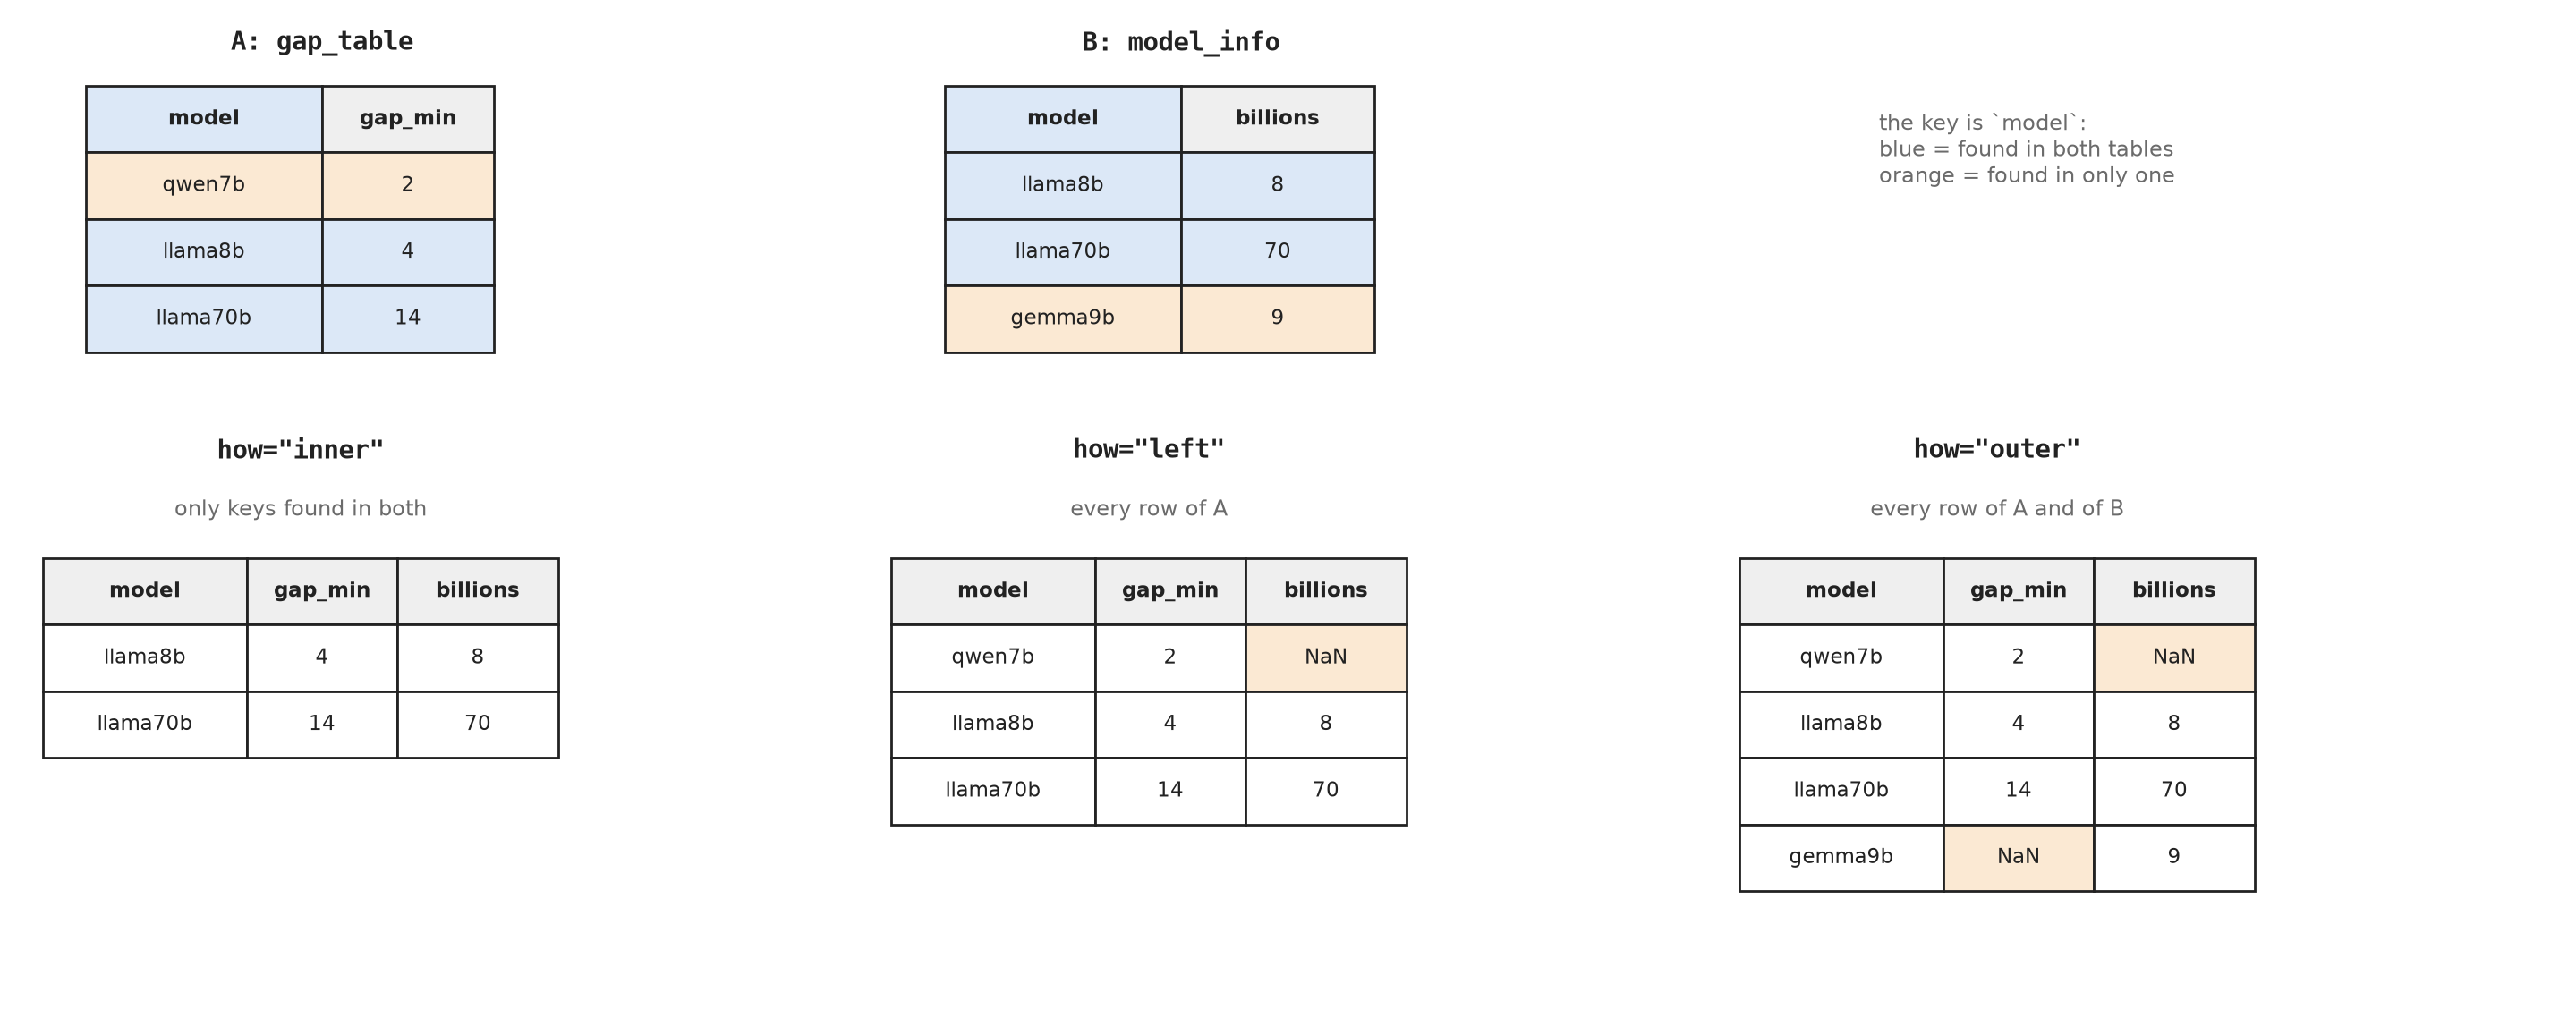

In [43]:
# a size table that misses one of our models (qwen32b) and has one we never ran (gemma9b)
other = pd.concat([model_info[model_info["model"] != "qwen32b"],
                   pd.DataFrame({"model": ["gemma9b"], "billions": [9]})], ignore_index=True)

# compare with gap_table (our 6 models): qwen32b is not here, gemma9b is new
print("models in gap_table:", sorted(gap_table["model"]))
print("models in other:    ", sorted(other["model"]))
other

models in gap_table: ['llama70b', 'llama8b', 'mistral24b', 'mistral7b', 'qwen32b', 'qwen7b']
models in other:     ['gemma9b', 'llama70b', 'llama8b', 'mistral24b', 'mistral7b', 'qwen7b']


,model,billions
0,llama8b,8
1,llama70b,70
2,mistral7b,7
3,mistral24b,24
4,qwen7b,7
5,gemma9b,9


In [44]:
for how in ["inner", "left", "outer"]:
    print(how, "->", len(gap_table.merge(other, on="model", how=how)), "rows")

# indicator=True adds a column that says where every row came from
gap_table.merge(other, on="model", how="outer", indicator=True)

inner -> 5 rows
left -> 6 rows
outer -> 7 rows


,model,gap_min,billions,_merge
0,gemma9b,NaN,9.0,right_only
1,llama70b,14.0,70.0,both
2,llama8b,4.0,8.0,both
3,mistral24b,4.0,24.0,both
4,mistral7b,3.0,7.0,both
5,qwen32b,4.0,NaN,left_only
6,qwen7b,2.0,7.0,both


Our 6 models against 6 sizes with one missing and one extra: `inner` gives 5 rows (the models in both), `left` gives our 6 models (`qwen32b` gets `NaN` for its size), and `outer` gives 7 (also `gemma9b`, with `NaN` for the time). The `_merge` column says `both`, `left_only` or `right_only` for each row.

**Which one to use?** `left` when the first table is the one we care about and we must not lose rows. `inner` when we only want complete rows. After any join, **count the rows** and look for `NaN`: it is the quickest way to notice keys that did not match.

### 5.5 Many rows, one match

The most common join: a big table (one row per message) and a small one (one row per conversation). Every message is matched with the conversation that has the same id, so a conversation's information is repeated on each of its messages. The key has a different name in each table, so we give `left_on` and `right_on`. With `how="left"` all messages are kept.

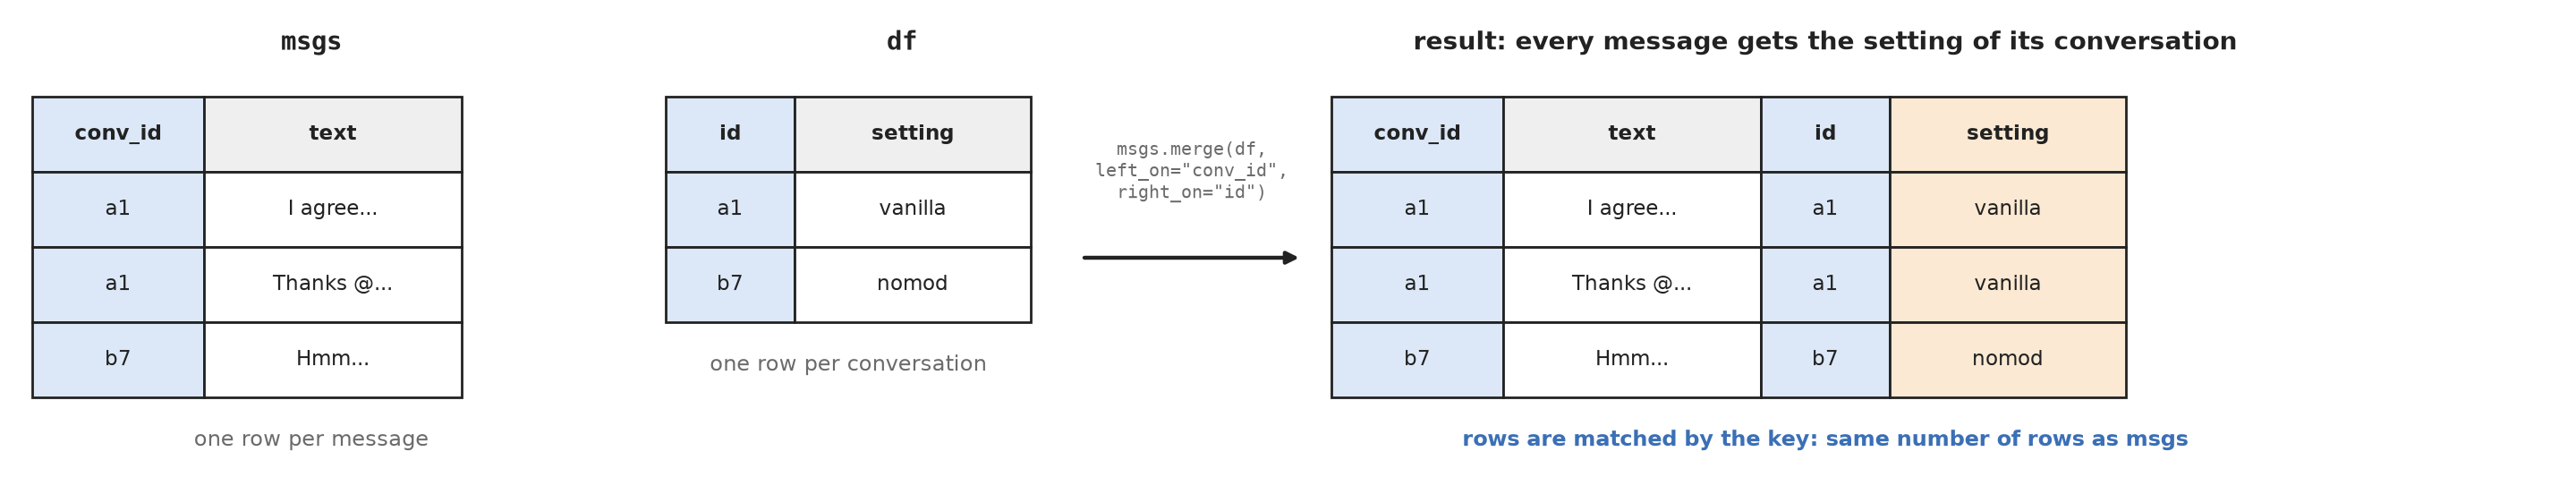

In [45]:
n_before = len(msgs)

# each message gets the setting of the conversation whose id equals its conv_id; how="left" keeps every message
msgs = msgs.merge(df[["id", "setting"]], left_on="conv_id", right_on="id", how="left").drop(columns="id")

# a left join must not add or remove messages, and every key must have been found
print("messages:", n_before, "before the join,", len(msgs), "after")
print("messages whose conversation was not found:", msgs["setting"].isna().sum())

# messages per setting (nomod has fewer: its conversations have 17 messages, not 32)
print()
print("messages per setting:")
for setting, n in msgs["setting"].value_counts().items():
    print(f"  {setting:<28} {n:>6}")

# the new column, on messages from different conversations
msgs[["conv_id", "speaker", "setting"]].sample(4, random_state=1)

messages: 18658 before the join, 18658 after
messages whose conversation was not found: 0

messages per setting:
  constructive_communications    5255
  erulemaking                    5231
  vanilla                        5138
  nomod                          3034


,conv_id,speaker,setting
6279,deb17200-932c-492e-8b88-256ccf0c760e,moderator,vanilla
12764,0a04f60e-6902-4a73-991f-101acea1d943,moderator,vanilla
10893,b0ed67b6-2905-4285-8b27-2a3663720ca6,auburn-parmesan,constructive_communications
9173,91d8f173-298e-4a6e-b633-36980a51deca,large-reduction,vanilla


The join gave every message the setting of its conversation, so we can now compare settings. We ask: do users write less when a moderator is present? We keep only the **users' messages**: the moderator's messages are shorter and exist only in the moderated settings, so including them would pull those settings down for a reason that has nothing to do with how the users behave. Then `groupby("setting")` takes the mean words per user message in each setting.

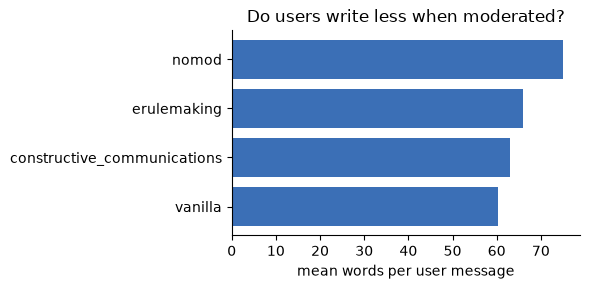

In [46]:
# the users' messages only
users = msgs[~msgs["is_mod"]]
# groupby: the mean words per setting
words_by_setting = users.groupby("setting")["n_words_clean"].mean().sort_values()

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(words_by_setting.index, words_by_setting.values, color="#3b6fb6")
ax.set_xlabel("mean words per user message")
ax.set_title("Do users write less when moderated?")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Your turn.** Join the users' mean words per writer (`usr_words`, from 5.2) with `model_info`. Which row has no size, and why? Try `how="inner"` too and see what changes.

In [47]:
# your code here

<details><summary>Solution</summary>

```python
usr_table = usr_words.reset_index().rename(columns={"written_by": "model", "n_words_clean": "mean_words"})

print(usr_table.merge(model_info, on="model", how="left"))    # "real comment" has no size: it is not a model
print(usr_table.merge(model_info, on="model", how="inner"))   # ...so the inner join drops it
```

</details>

### Findings: Part 5

- `groupby(...)[column].function()` computes a statistic for every group; `agg` computes several at once. `diff` inside a `groupby` stays within each group.
- Time per conversation depends on the model: `llama70b` takes about 14 minutes, the others 2 to 4.
- `concat` stacks tables with the same columns (rows) or puts tables with the same rows side by side (`axis=1`, matched by label). It does not look anything up.
- `merge` joins two tables through a key. With a small second table (model sizes) we saw that the largest model is the slowest.
- `how=` decides what happens to keys that do not match: `inner` keeps only the matches, `left` keeps every row of the first table, `outer` keeps all rows. After a join, count the rows and look for `NaN`.
- Users write longer messages in the `nomod` conversations (about 75 words) than in any moderated setting (60 to 66). This is a pattern in the data, not proof that the moderator causes it: the models and topics differ as well.